In [ ]:
import pathlib as pl
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter
from scipy.integrate import cumulative_trapezoid

DATA_DIR = pl.Path("recorded-data")

paths = {
    "D25":   DATA_DIR / "Log_30.04.2026_09.03.30-25per.txt",
    "D50":   DATA_DIR / "Log_30.04.2026_09.06.16-50per.txt",
    "D75":   DATA_DIR / "Log_30.04.2026_09.09.11-75per.txt",
    "D100":  DATA_DIR / "Log_30.04.2026_09.14.01-100per.txt",
    "pmD25": DATA_DIR / "Log_30.04.2026_09.15.49-pm25per.txt",
}

FSAMPLE_HZ = 500  # from the `fsample=500Hz` header line


def load_log(path: pl.Path) -> pd.DataFrame:
    """Read a Serial.ICE log file (semicolon-separated, first line `fsample=...`)."""
    df = pd.read_csv(path, sep=";", skiprows=1, skipinitialspace=True)
    df.columns = [c.strip() for c in df.columns]
    df["t/s"] = df["Time/ms"] / 1000.0
    return df


dfs = {key: load_log(paths[key]) for key in ("D25", "D50", "D75", "D100")}

division_factor = "25" # tangent through 25% to normalize it

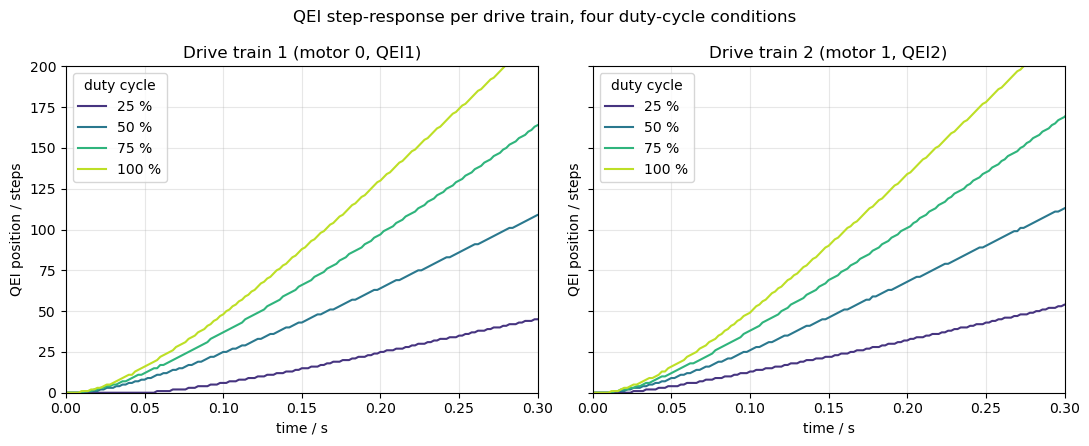

In [2]:
FIG_DIR = pl.Path("../01_RTP-Ausarbeitung/figure")
FIG_DIR.mkdir(parents=True, exist_ok=True)

DRIVES = [("D25", "25 %"), ("D50", "50 %"), ("D75", "75 %"), ("D100", "100 %")]
DRIVE_COLORS = plt.cm.viridis([0.15, 0.4, 0.65, 0.9])

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for (key, label), color in zip(DRIVES, DRIVE_COLORS):
    axes[0].plot(dfs[key]["t/s"], dfs[key]["QEI1/steps"], label=label, color=color)
    axes[1].plot(dfs[key]["t/s"], dfs[key]["QEI2/steps"], label=label, color=color)
axes[0].set_title("Drive train 1 (motor 0, QEI1)")
axes[1].set_title("Drive train 2 (motor 1, QEI2)")
axes[0].set_ylim(0, 200)
axes[0].set_xlim(0, 0.3)
axes[1].set_xlim(0, 0.3)

for ax in axes:
    ax.set_xlabel("time / s")
    ax.set_ylabel("QEI position / steps")
    ax.grid(True, alpha=0.3)
    ax.legend(title="duty cycle", loc="upper left")
fig.suptitle("QEI step-response per drive train, four duty-cycle conditions")
fig.tight_layout()
fig.savefig(FIG_DIR / "drive-position-comparison.pdf", bbox_inches="tight")
#fig.savefig(FIG_DIR / "drive-position-comparison.png", dpi=200, bbox_inches="tight")
plt.show()



In [3]:
# # Ref cell 


# # sys2 IT1 identification (no dead time) with annotated plot
# t = data2[:, 0]
# u = data2[:, 1]  # input y(t)
# x = data2[:, 2]  # output x(t)

# # Plant proportional factor known from setup (input scaling K_p = 10).
# K_p_plant = 10.0

# # Step detection on input (0 -> 2).
# trigger_candidates = np.where((u[:-1] < 1.0) & (u[1:] >= 1.0))[0]
# trigger_idx = trigger_candidates[0] + 1 if len(trigger_candidates) > 0 else 0
# t_step = t[trigger_idx]

# # Input step height.
# u0 = np.mean(u[:max(1, trigger_idx)])
# u_inf = np.mean(u[trigger_idx:])
# du = u_inf - u0

# # Asymptotic tangent (lim t->inf) from last part of the measured response.
# tail_start = int(0.75 * len(t))
# if len(t) - tail_start < 5:
#     tail_start = max(trigger_idx, len(t) - 5)
# slope_inf, intercept_inf = np.polyfit(t[tail_start:], x[tail_start:], 1)

# # K_I from asymptotic slope: slope_inf = K_p_plant * K_I * delta_u
# # (the IT1 is preceded by a proportional element with K_p = 10).
# K_I = slope_inf / (du * K_p_plant) if abs(du) > 1e-12 else np.nan

# # Intersection of asymptotic tangent with time axis (x = 0).
# t_intersect = -intercept_inf / slope_inf if abs(slope_inf) > 1e-12 else np.nan

# # T_1 from tangent intersection relative to step origin (no dead time).
# T_1 = t_intersect - t_step if np.isfinite(t_intersect) else np.nan
# if np.isfinite(T_1):
#     T_1 = max(T_1, 1e-6)

# # IT1 model response to a step (no dead time) for visual comparison.
# x0 = np.mean(x[:max(1, trigger_idx)])
# tau = t - t_step
# tau_pos = np.maximum(tau, 0.0)
# if np.isfinite(T_1):
#     x_model = x0 + K_p_plant * K_I * du * (tau_pos - T_1 * (1.0 - np.exp(-tau_pos / T_1)))
# else:
#     x_model = x0 + K_p_plant * K_I * du * tau_pos

# # Pure-I reference: K_p_plant * K_I * integral(u(t) - u0) dt, plotted as dotted line.
# # Differs from the measured IT1 response by the first-order lag T_1.
# u_eff = u - u0
# x_int = x0 + K_p_plant * K_I * np.concatenate(([0.0], np.cumsum(0.5 * (u_eff[1:] + u_eff[:-1]) * np.diff(t))))

# # Asymptotic tangent line over plotting range.
# tangent_inf = slope_inf * t + intercept_inf

# # Plot: left input, right output identification.
# fig, (ax_in, ax_out) = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={'width_ratios': [1, 2]})

# ax_in.plot(t, u, color='tab:orange', label='y(t) input', linewidth=2)
# ax_in.axvline(t_step, color='black', linestyle='--', label='step origin')
# ax_in.axhline(u_inf, color='tab:orange', linestyle=':', label=r'$u_\infty$')
# ax_in.set_title('sys2 input signal')
# ax_in.set_xlabel('$t/s$')
# ax_in.set_ylabel('$y(t)$')
# ax_in.grid()
# ax_in.legend(loc='best')

# ax_out.plot(t, x, label='x(t) measured', linewidth=2)
# ax_out.plot(t, x_model, ':', label='IT1 model')
# ax_out.plot(t, x_int, linestyle=(0, (1, 1)), color='tab:red', label=r'$K_p \cdot K_I \int u\,dt$ (pure I)')
# ax_out.plot(t, tangent_inf, '--', label=r'$\lim_{t\to\infty}$ tangent')

# ax_out.axvline(t_step, color='black', linestyle='--', label='step origin')
# if np.isfinite(t_intersect):
#     ax_out.axvline(t_intersect, color='tab:green', linestyle='--', label='t-axis intersection')
#     ax_out.scatter([t_intersect], [0.0], color='tab:green', zorder=5)

# # Slope triangle on the asymptotic tangent: delta t = 1 s.
# triangle_shift = 1.0
# triangle_base = t_step + 0.5 + triangle_shift
# t_tri0 = max(triangle_base, t[0])
# t_tri1 = min(t_tri0 + 1.0, t[-1])
# if t_tri1 - t_tri0 < 1e-9:
#     t_tri0 = max(t[-1] - 1.0, t[0])
#     t_tri1 = t[-1]
# x_tri0 = slope_inf * t_tri0 + intercept_inf
# x_tri1 = slope_inf * t_tri1 + intercept_inf

# ax_out.plot([t_tri0, t_tri1], [x_tri0, x_tri0], color='tab:blue', linewidth=2)
# ax_out.plot([t_tri1, t_tri1], [x_tri0, x_tri1], color='tab:blue', linewidth=2)
# ax_out.text((t_tri0 + t_tri1) / 2.0, x_tri0, '1 s', color='tab:blue', ha='center', va='bottom')
# ax_out.text(t_tri1, (x_tri0 + x_tri1) / 2.0, r'$K_p \cdot K_I \cdot \Delta u$', color='tab:blue', ha='left', va='center')

# # Keep readable scale from measured output.
# y_min = np.min(x)
# y_max = np.max(x)
# y_pad = 0.1 * (y_max - y_min) if y_max > y_min else 1.0
# ax_out.set_xlim(t[0], t[-1])
# ax_out.set_ylim(y_min - y_pad, y_max + y_pad)

# ax_out.set_title('sys2: IT1 identification with marked parameters')
# ax_out.set_xlabel('$t/s$')
# ax_out.set_ylabel('$x(t)$')
# ax_out.grid()
# ax_out.legend(loc='upper left', bbox_to_anchor=(1.02, 1.0), borderaxespad=0.0)

# # Annotation box with identified parameters, placed below the legend (outside the plot, on the right).
# annot_text = (
#     f'$K_p$ = {K_p_plant:.4f} (given)\n'
#     f'$K_I$ = {K_I:.4f} 1/s\n'
#     f'$T_1$ = {T_1:.4f} s\n'
#     f'slope$_\\infty$ = {slope_inf:.4f}\n'
#     f'$\\Delta u$ = {du:.4f}'
# )
# ax_out.text(
#     1.02, 0.0, annot_text,
#     transform=ax_out.transAxes, va='bottom', ha='left',
#     bbox=dict(boxstyle='round', facecolor='white', alpha=0.85)
# )

# plt.tight_layout()
# plt.subplots_adjust(right=0.78)
# plt.show()
# fig.savefig('figure_out/sys2_it1_identification.' + fileformat, dpi=resolution, bbox_inches='tight')

# print('Estimated sys2 IT1 parameters (with K_p = 10 given):')
# print(f'K_p (given) = {K_p_plant:.6f}')
# print(f'K_I = {K_I:.6f} 1/s')
# print(f'T_1 = {T_1:.6f} s')
# print('Transfer function (IT1, including K_p):')
# print(f'G(s) = ({K_p_plant:.6f} * {K_I:.6f}) / (s * ({T_1:.6f} s + 1))')
